## 1. Setup e Caricamento

In questa sezione importeremo le librerie necessarie per l'analisi e caricheremo i CSV dal dataset MovieLens.

**Librerie utilizzate:**
- **pandas**: manipolazione e analisi dati strutturati (CSV, tabelle)
- **numpy**: operazioni numeriche e statistiche
- **matplotlib e seaborn**: visualizzazione di grafici


# Analisi e Arricchimento Dataset MovieLens (ml-latest-small)

## Obiettivo
Esplorare il dataset MovieLens e identificare opportunità di arricchimento, in particolare per le descrizioni dei film. 
Questo notebook serve come base per integrare dati da TMDb al fine di arricchire il nostro surrogato didattico per la tesi.

## Struttura
1. **Setup e Caricamento**: importazioni e caricamento dei CSV
2. **Esplorazione Iniziale**: dimensioni, tipi, dati mancanti
3. **Analisi Descrittiva**: statistiche per ciascun dataset
4. **Relazioni tra Dataset**: come i file si connettono
5. **Opportunità di Arricchimento**: cosa manca e come TMDb può aiutare


In [1]:
# Importazione delle librerie
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configurazione base per visualizzazioni
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Definizione del percorso ai dati
data_path = Path("../datasets/raw/ml-latest-small")

# Caricamento dei file CSV
# Ogni file contiene diverse informazioni sui film, rating, tag e link
movies = pd.read_csv(data_path / "movies.csv")
ratings = pd.read_csv(data_path / "ratings.csv")
tags = pd.read_csv(data_path / "tags.csv")
links = pd.read_csv(data_path / "links.csv")

print("✓ Dati caricati con successo!")
print(f"  - movies.csv: {movies.shape[0]} film")
print(f"  - ratings.csv: {ratings.shape[0]} rating")
print(f"  - tags.csv: {tags.shape[0]} tag")
print(f"  - links.csv: {links.shape[0]} film con link esterni")

✓ Dati caricati con successo!
  - movies.csv: 9742 film
  - ratings.csv: 100836 rating
  - tags.csv: 3683 tag
  - links.csv: 9742 film con link esterni


## 2. Esplorazione Iniziale: Struttura e Completezza dei Dati

Analizziamo la struttura di base di ogni dataset: numero di righe/colonne, tipi di dati e valori mancanti.
Questo ci aiuta a capire cosa abbiamo e cosa potrebbe mancare.


In [2]:
# Esaminiamo la struttura del dataset movies
print("=" * 80)
print("MOVIES.CSV")
print("=" * 80)

print("\nPrime 5 righe:")
print(movies.head())

print("\nTipi di dati:")
print(movies.dtypes)

print("\nDimensioni:")
print(f"  Righe: {movies.shape[0]}, Colonne: {movies.shape[1]}")

print("\nValori mancanti:")
print(movies.isna().sum())

# print("\nDescrizione statistica:")
# print(movies.describe()) # non serve a nulla

MOVIES.CSV

Prime 5 righe:
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  

Tipi di dati:
movieId    int64
title        str
genres       str
dtype: object

Dimensioni:
  Righe: 9742, Colonne: 3

Valori mancanti:
movieId    0
title      0
genres     0
dtype: int64


In [3]:
# Esaminiamo ratings.csv
print("\n" + "=" * 80)
print("RATINGS.CSV")
print("=" * 80)
print("\nPrime 5 righe:")
print(ratings.head())

print("\nTipi di dati:")
print(ratings.dtypes)

print("\nDimensioni:")
print(f"  Righe: {ratings.shape[0]}, Colonne: {ratings.shape[1]}")

print("\nValori mancanti:")
print(ratings.isna().sum())

print("\nDescrizione statistica (focus sui rating):")
print(ratings.describe())


RATINGS.CSV

Prime 5 righe:
   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931

Tipi di dati:
userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

Dimensioni:
  Righe: 100836, Colonne: 4

Valori mancanti:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Descrizione statistica (focus sui rating):
              userId        movieId         rating     timestamp
count  100836.000000  100836.000000  100836.000000  1.008360e+05
mean      326.127564   19435.295718       3.501557  1.205946e+09
std       182.618491   35530.987199       1.042529  2.162610e+08
min         1.000000       1.000000       0.500000  8.281246e+08
25%       177.000000    1199.000000       3.000000  1.019124e+09
50%       325.000000    2991.000000       3.500000  1.186087e+09

In [4]:
# Esaminiamo tags.csv
print("\n" + "=" * 80)
print("TAGS.CSV")
print("=" * 80)
print("\nPrime 5 righe:")
print(tags.head())

print("\nTipi di dati:")
print(tags.dtypes)

print("\nDimensioni:")
print(f"  Righe: {tags.shape[0]}, Colonne: {tags.shape[1]}")

print("\nValori mancanti:")
print(tags.isna().sum())

# Esaminiamo links.csv
print("\n" + "=" * 80)
print("LINKS.CSV")
print("=" * 80)
print("\nPrime 5 righe:")
print(links.head())

print("\nTipi di dati:")
print(links.dtypes)

print("\nDimensioni:")
print(f"  Righe: {links.shape[0]}, Colonne: {links.shape[1]}")

print("\nValori mancanti:")
print(links.isna().sum())


TAGS.CSV

Prime 5 righe:
   userId  movieId              tag   timestamp
0       2    60756            funny  1445714994
1       2    60756  Highly quotable  1445714996
2       2    60756     will ferrell  1445714992
3       2    89774     Boxing story  1445715207
4       2    89774              MMA  1445715200

Tipi di dati:
userId       int64
movieId      int64
tag            str
timestamp    int64
dtype: object

Dimensioni:
  Righe: 3683, Colonne: 4

Valori mancanti:
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

LINKS.CSV

Prime 5 righe:
   movieId  imdbId   tmdbId
0        1  114709    862.0
1        2  113497   8844.0
2        3  113228  15602.0
3        4  114885  31357.0
4        5  113041  11862.0

Tipi di dati:
movieId      int64
imdbId       int64
tmdbId     float64
dtype: object

Dimensioni:
  Righe: 9742, Colonne: 3

Valori mancanti:
movieId    0
imdbId     0
tmdbId     8
dtype: int64


## 3. Analisi Descrittiva: Distribuzioni e Pattern Interessanti

Ora analizziamo i dati in profondità: come sono distribuiti i rating? Quali sono i generi più comuni? 
Quanti film non hanno informazioni su IMDb o TMDb?


ANALISI 1: GENERI DEI FILM

Film per genere:
genres
Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
Name: count, dtype: int64


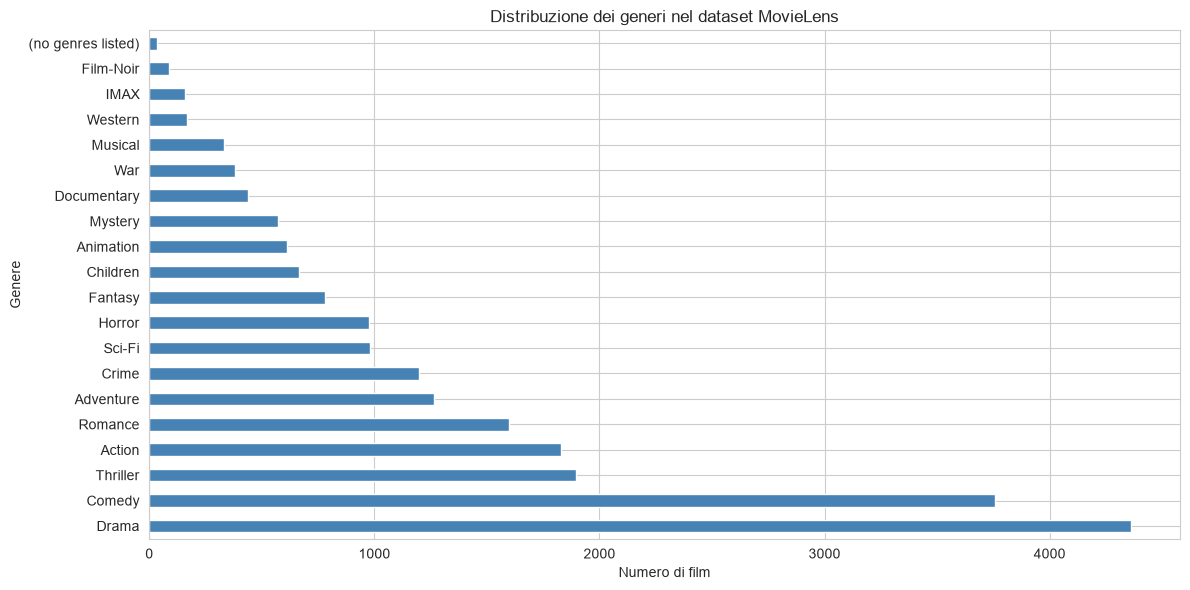


Total unico generi: 20


In [5]:
# ANALISI 1: Generi dei film
# Nel dataset, i generi sono separati da "|" in una singola stringa
# Dobbiamo "esplodere" questa colonna per capire meglio la distribuzione

print("=" * 80)
print("ANALISI 1: GENERI DEI FILM")
print("=" * 80)

# Creiamo una copia e "esplodiamo" i generi
genres_exploded = movies.copy()
genres_exploded['genres'] = genres_exploded['genres'].str.split('|')
genres_exploded = genres_exploded.explode('genres')

# Contiamo quanti film per genere
genre_counts = genres_exploded['genres'].value_counts()
print("\nFilm per genere:")
print(genre_counts)

# Visualizziamo con un grafico
fig, ax = plt.subplots(figsize=(12, 6))
genre_counts.plot(kind='barh', ax=ax, color='steelblue')
ax.set_xlabel('Numero di film')
ax.set_ylabel('Genere')
ax.set_title('Distribuzione dei generi nel dataset MovieLens')
plt.tight_layout()
plt.show()

print(f"\nTotal unico generi: {genre_counts.shape[0]}")


ANALISI 2: DISTRIBUZIONE DEI RATING

Statistiche dei rating:
  Media: 3.50
  Mediana: 3.50
  Std Dev: 1.04
  Min: 0.5, Max: 5.0

Conteggio per valore di rating:
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


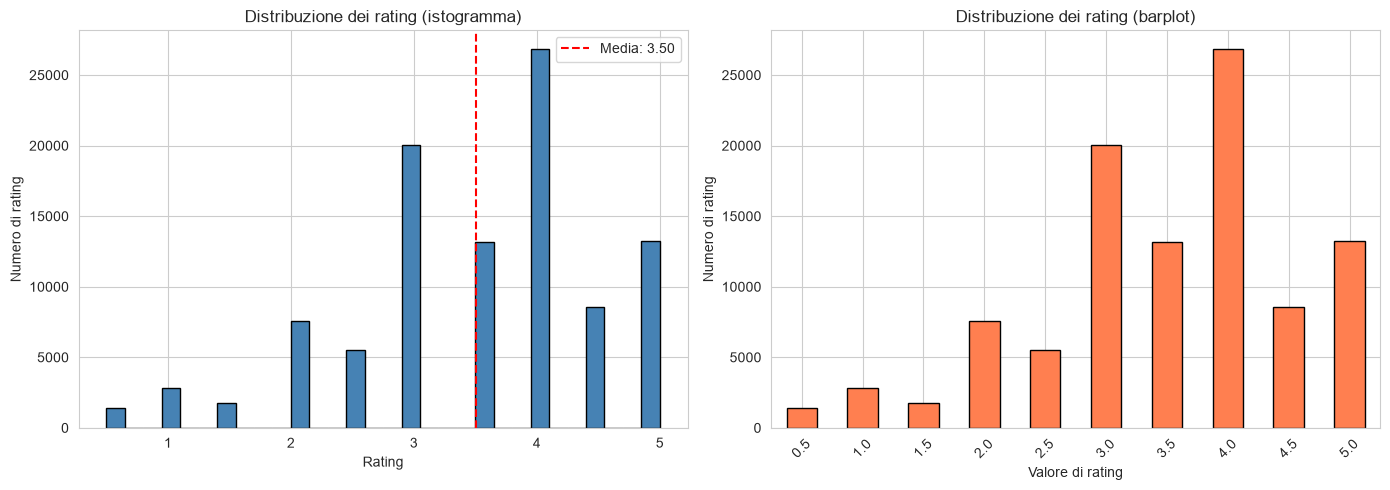

In [6]:
# ANALISI 2: Distribuzione dei rating
print("\n" + "=" * 80)
print("ANALISI 2: DISTRIBUZIONE DEI RATING")
print("=" * 80)

print("\nStatistiche dei rating:")
print(f"  Media: {ratings['rating'].mean():.2f}")
print(f"  Mediana: {ratings['rating'].median():.2f}")
print(f"  Std Dev: {ratings['rating'].std():.2f}")
print(f"  Min: {ratings['rating'].min()}, Max: {ratings['rating'].max()}")

print("\nConteggio per valore di rating:")
rating_counts = ratings['rating'].value_counts().sort_index()
print(rating_counts)

# Visualizziamo la distribuzione con istogramma
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Istogramma
axes[0].hist(ratings['rating'], bins=30, color='steelblue', edgecolor='black')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Numero di rating')
axes[0].set_title('Distribuzione dei rating (istogramma)')
axes[0].axvline(ratings['rating'].mean(), color='red', linestyle='--', label=f'Media: {ratings["rating"].mean():.2f}')
axes[0].legend()

# Barplot per ogni valore
rating_counts.plot(kind='bar', ax=axes[1], color='coral', edgecolor='black')
axes[1].set_xlabel('Valore di rating')
axes[1].set_ylabel('Numero di rating')
axes[1].set_title('Distribuzione dei rating (barplot)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.show()


ANALISI 3: TAG PIÙ COMUNI

Total tag univoci: 1589
Total tag applicati: 3683

Top 20 tag più comuni:
tag
In Netflix queue      131
atmospheric            36
superhero              24
thought-provoking      24
funny                  23
Disney                 23
surreal                23
religion               22
sci-fi                 21
dark comedy            21
quirky                 21
psychology             21
suspense               20
twist ending           19
visually appealing     19
crime                  19
politics               18
music                  16
time travel            16
mental illness         16
Name: count, dtype: int64


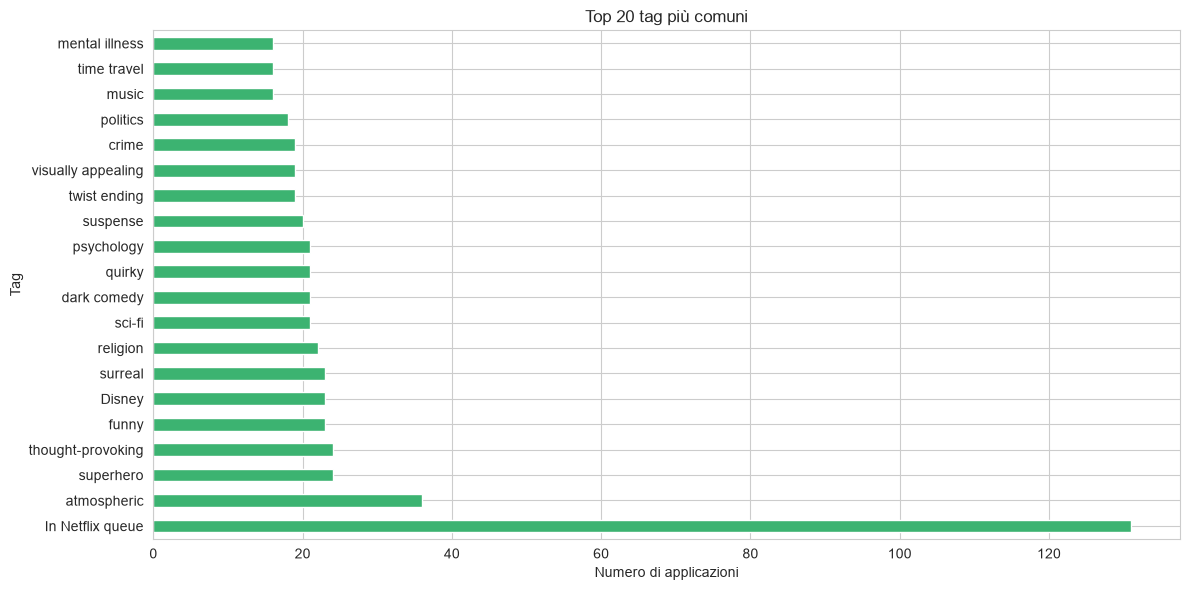

In [7]:
# ANALISI 3: Tag più comuni
print("\n" + "=" * 80)
print("ANALISI 3: TAG PIÙ COMUNI")
print("=" * 80)

print(f"\nTotal tag univoci: {tags['tag'].nunique()}")
print(f"Total tag applicati: {len(tags)}")

# Top 20 tag
top_tags = tags['tag'].value_counts().head(20)
print("\nTop 20 tag più comuni:")
print(top_tags)

# Visualizziamo
fig, ax = plt.subplots(figsize=(12, 6))
top_tags.plot(kind='barh', ax=ax, color='mediumseagreen')
ax.set_xlabel('Numero di applicazioni')
ax.set_ylabel('Tag')
ax.set_title('Top 20 tag più comuni')
plt.tight_layout()
plt.show()

## 4. Relazioni tra i Dataset

Analizziamo come i diversi dataset si connettono attraverso `movieId` e esaminiamo 
la copertura: quanti film hanno rating? Quanti hanno tag? Quanti hanno link a IMDb/TMDb?


In [8]:
# ANALISI 4: Copertura dei dati tra dataset
print("=" * 80)
print("ANALISI 4: COPERTURA DEI DATI TRA DATASET")
print("=" * 80)

# Film unici in ogni dataset
movies_set = set(movies['movieId'])
ratings_movies = set(ratings['movieId'])
tags_movies = set(tags['movieId'])
links_movies = set(links['movieId'])

print(f"\nFilm totali: {len(movies_set)}")
print(f"Film con rating: {len(ratings_movies)} ({len(ratings_movies)/len(movies_set)*100:.1f}%)")
print(f"Film con tag: {len(tags_movies)} ({len(tags_movies)/len(movies_set)*100:.1f}%)")
print(f"Film con link: {len(links_movies)} ({len(links_movies)/len(movies_set)*100:.1f}%)")

# Intersezioni
print(f"\nFilm con rating E link: {len(ratings_movies & links_movies)} ({len(ratings_movies & links_movies)/len(movies_set)*100:.1f}%)")
print(f"Film con rating E tag: {len(ratings_movies & tags_movies)} ({len(ratings_movies & tags_movies)/len(movies_set)*100:.1f}%)")
print(f"Film con tag E link: {len(tags_movies & links_movies)} ({len(tags_movies & links_movies)/len(movies_set)*100:.1f}%)")

# Film senza rating
no_rating_films = movies_set - ratings_movies
print(f"\nFilm SENZA rating: {len(no_rating_films)} ({len(no_rating_films)/len(movies_set)*100:.1f}%)")

# Film senza link
no_link_films = movies_set - links_movies
print(f"Film SENZA link: {len(no_link_films)} ({len(no_link_films)/len(movies_set)*100:.1f}%)")

ANALISI 4: COPERTURA DEI DATI TRA DATASET

Film totali: 9742
Film con rating: 9724 (99.8%)
Film con tag: 1572 (16.1%)
Film con link: 9742 (100.0%)

Film con rating E link: 9724 (99.8%)
Film con rating E tag: 1554 (16.0%)
Film con tag E link: 1572 (16.1%)

Film SENZA rating: 18 (0.2%)
Film SENZA link: 0 (0.0%)



ANALISI 5: DENSITÀ DEI RATING PER FILM

Statistiche su rating per film:
  Media: 10.37 rating/film
  Mediana: 3.00
  Min: 1, Max: 329

Film con almeno 1 rating: 9724
Film con almeno 10 rating: 2269
Film con almeno 50 rating: 450
Film con almeno 100 rating: 138


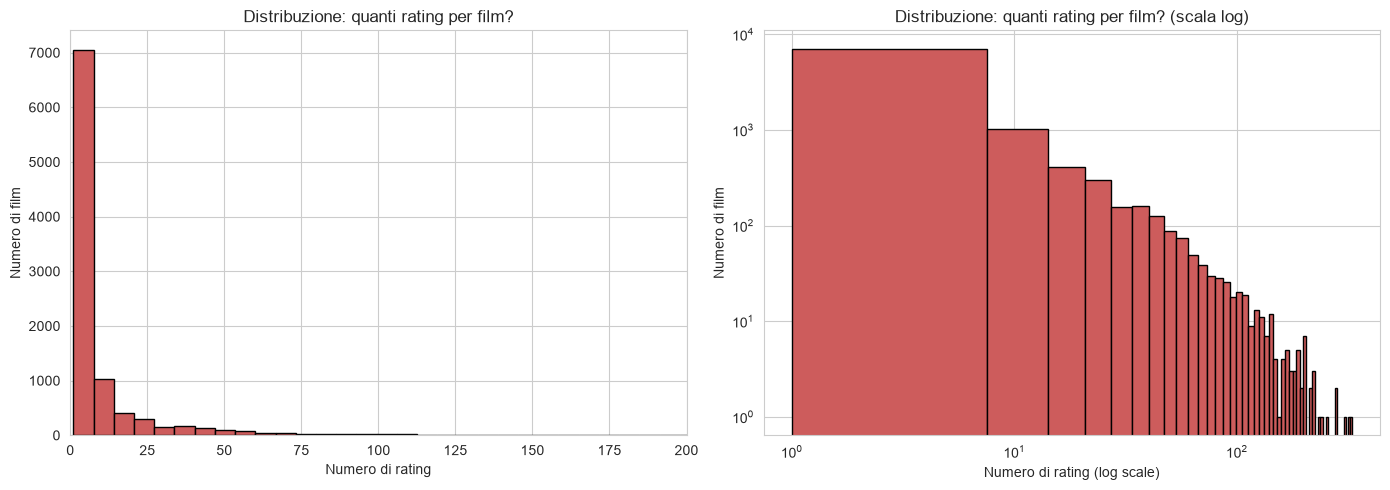

In [9]:
# ANALISI 5: Densità dei rating (quanti rating per film?)
print("\n" + "=" * 80)
print("ANALISI 5: DENSITÀ DEI RATING PER FILM")
print("=" * 80)

# Contiamo quanti rating ha ogni film
ratings_per_movie = ratings.groupby('movieId').size()

print(f"\nStatistiche su rating per film:")
print(f"  Media: {ratings_per_movie.mean():.2f} rating/film")
print(f"  Mediana: {ratings_per_movie.median():.2f}")
print(f"  Min: {ratings_per_movie.min()}, Max: {ratings_per_movie.max()}")

# Quanti film hanno almeno N rating?
print(f"\nFilm con almeno 1 rating: {(ratings_per_movie >= 1).sum()}")
print(f"Film con almeno 10 rating: {(ratings_per_movie >= 10).sum()}")
print(f"Film con almeno 50 rating: {(ratings_per_movie >= 50).sum()}")
print(f"Film con almeno 100 rating: {(ratings_per_movie >= 100).sum()}")

# Visualizziamo la distribuzione
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Istogramma
axes[0].hist(ratings_per_movie, bins=50, color='indianred', edgecolor='black')
axes[0].set_xlabel('Numero di rating')
axes[0].set_ylabel('Numero di film')
axes[0].set_title('Distribuzione: quanti rating per film?')
axes[0].set_xlim(left=0, right=200)  # Zoom su range più significativo

# In scala logaritmica per vedere meglio la distribuzione
axes[1].hist(ratings_per_movie, bins=50, color='indianred', edgecolor='black')
axes[1].set_xlabel('Numero di rating (log scale)')
axes[1].set_ylabel('Numero di film')
axes[1].set_title('Distribuzione: quanti rating per film? (scala log)')
axes[1].set_xscale('log')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

## 5. Opportunità di Arricchimento: Cosa Manca?

Il dataset MovieLens è utile per il testing, ma come surrogato didattico ha limitazioni:
- I film hanno solo **title** e **genres**, ma mancano **descrizioni** dettagliate (sinossi, plot)
- Non ci sono **metadati** come anno di uscita, durata, regista, cast
- I **links** collegano a IMDb e TMDb, ma non contengono i dati effettivi

**Idea**: usare le **tmdbId** dai link per arricchire con dati da TMDb API


In [10]:
# ANALISI 6: Disponibilità di link a TMDb
print("=" * 80)
print("ANALISI 6: DISPONIBILITÀ DI LINK A TMDb")
print("=" * 80)

print(f"\nTotal film nel dataset: {len(movies)}")
print(f"Film con tmdbId nel file links.csv: {links['tmdbId'].notna().sum()}")
print(f"Film SENZA tmdbId: {links['tmdbId'].isna().sum()}")

print(f"Numero Film senza tmdbId nel file links.csv: {links['tmdbId'].isna().sum()}")
print(f"Film senza tmdbId nel file links.csv:\n {links[links['tmdbId'].isna()].head(10)}")

# Percentuale di copertura
coverage = (links['tmdbId'].notna().sum() / len(movies)) * 100
print(f"\nCopertura TMDb: {coverage:.1f}%")

# Uniamo movies con links per vedere i dati
movies_with_links = movies.merge(links[['movieId', 'imdbId', 'tmdbId']], 
                                  on='movieId', how='left')

print("\nPrime film con loro link TMDb:")
print(movies_with_links[movies_with_links['tmdbId'].notna()][['movieId', 'title', 'tmdbId']].head(10))

print("\nFilm senza link:")
print(movies_with_links[movies_with_links['tmdbId'].isna()][['movieId', 'title', 'imdbId', 'tmdbId']].head(10))


# Quanti film hanno sia rating che tmdbId?
movies_with_rating_and_tmdb = set(ratings['movieId']) & set(links[links['tmdbId'].notna()]['movieId'])
print(f"\nFilm con RATING e TMDB ID: {len(movies_with_rating_and_tmdb)} ({len(movies_with_rating_and_tmdb)/len(movies_set)*100:.1f}%)")
print("→ Questi sono i candidati ideali per l'arricchimento!")

ANALISI 6: DISPONIBILITÀ DI LINK A TMDb

Total film nel dataset: 9742
Film con tmdbId nel file links.csv: 9734
Film SENZA tmdbId: 8
Numero Film senza tmdbId nel file links.csv: 8
Film senza tmdbId nel file links.csv:
       movieId  imdbId  tmdbId
624       791  113610     NaN
843      1107  102336     NaN
2141     2851   81454     NaN
3027     4051   56600     NaN
5532    26587   92337     NaN
5854    32600  377059     NaN
6059    40697  105946     NaN
7382    79299  874957     NaN

Copertura TMDb: 99.9%

Prime film con loro link TMDb:
   movieId                               title   tmdbId
0        1                    Toy Story (1995)    862.0
1        2                      Jumanji (1995)   8844.0
2        3             Grumpier Old Men (1995)  15602.0
3        4            Waiting to Exhale (1995)  31357.0
4        5  Father of the Bride Part II (1995)  11862.0
5        6                         Heat (1995)    949.0
6        7                      Sabrina (1995)  11860.0
7        

### NOTA:
Per 8 film manca il tmdbId ma c'è l'imdbId eventualmente prima tradurre i tmdbId mancanti e poi procedere con il merge dei dati


ANALISI 7: ANNI DI USCITA DEI FILM

Anni disponibili:
  Min: 1902.0, Max: 2018.0
  Film senza anno: 24

Distribuzione per decennio:
decade
1900       3
1910       7
1920      37
1930     136
1940     197
1950     279
1960     401
1970     499
1980    1177
1990    2209
2000    2846
2010    1927
Name: count, dtype: Int64


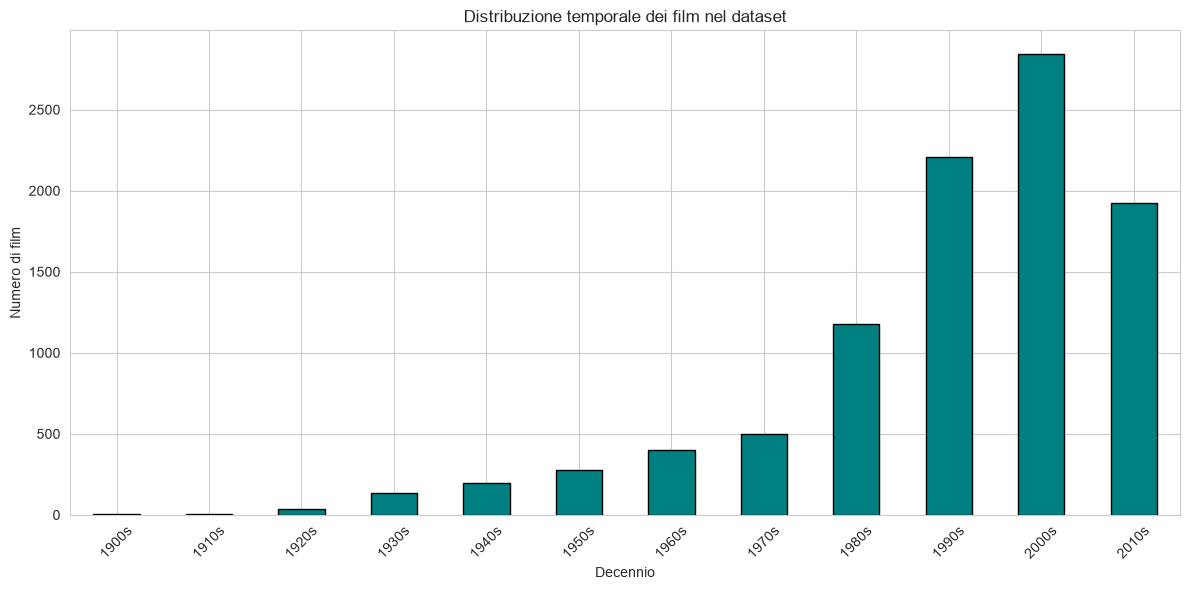

In [11]:
# ANALISI 7: Anni di uscita dei film (estratti dal title)
print("\n" + "=" * 80)
print("ANALISI 7: ANNI DI USCITA DEI FILM")
print("=" * 80)

# I film hanno formato: "Title (year)"
# Estrapiamo l'anno con una regex

import re

def extract_year(title):
    """Estrae l'anno dal title nel formato 'Title (YYYY)'"""
    match = re.search(r'\((\d{4})\)$', title)
    return int(match.group(1)) if match else None

movies_with_year = movies.copy()

movies_with_year['year'] = movies_with_year['title'].apply(extract_year)

print(f"\nAnni disponibili:")
print(f"  Min: {movies_with_year['year'].min()}, Max: {movies_with_year['year'].max()}")
print(f"  Film senza anno: {movies_with_year['year'].isna().sum()}")

print("\nDistribuzione per decennio:")
movies_with_year['decade'] = (movies_with_year['year'] // 10 * 10).astype('Int64')
decade_counts = movies_with_year['decade'].value_counts().sort_index()
print(decade_counts)

# Visualizziamo
fig, ax = plt.subplots(figsize=(12, 6))
decade_counts.plot(kind='bar', ax=ax, color='teal', edgecolor='black')
ax.set_xlabel('Decennio')
ax.set_ylabel('Numero di film')
ax.set_title('Distribuzione temporale dei film nel dataset')
ax.set_xticklabels([f"{int(d)}s" if pd.notna(d) else 'N/A' for d in decade_counts.index], rotation=45)
plt.tight_layout()
plt.show()

## 6. Preparazione per l'Arricchimento TMDb

Ora abbiamo una visione completa del dataset. Identifichiamo il subset di film da arricchire con TMDb:
- Devono avere un `tmdbId` valido (per il lookup)
- Idealmente devono avere rating (per validare il surrogato in contesto di ranking/reranking)
- Possiamo iniziare con un sottoinsieme per testare la pipeline prima di scalare


In [12]:
# Creiamo un dataframe di candidati per l'arricchimento TMDb
# Uniremo informazioni da movies, ratings, tags e links

print("=" * 80)
print("PREPARAZIONE: CANDIDATI PER ARRICCHIMENTO TMDb")
print("=" * 80)

# Partiamo da movies e aggiungiamo le informazioni di links
enrichment_base = movies_with_links.copy()
# enrichment_base = movies.copy()
enrichment_base['year'] = enrichment_base['title'].apply(extract_year)

# Aggiungiamo il numero di rating per film
ratings_count = ratings.groupby('movieId').size().reset_index(name='rating_count')
enrichment_base = enrichment_base.merge(ratings_count, on='movieId', how='left')

# Aggiungiamo il numero di tag per film
tags_count = tags.groupby('movieId').size().reset_index(name='tags_count')
enrichment_base = enrichment_base.merge(tags_count, on='movieId', how='left')

# Aggiungiamo il rating medio per film
avg_rating = ratings.groupby('movieId')['rating'].mean().reset_index(name='avg_rating')
enrichment_base = enrichment_base.merge(avg_rating, on='movieId', how='left')

# Filtriamo i candidati: devono avere tmdbId e almeno 1 rating
candidates_with_tmdbId_and_rating = enrichment_base[
    (enrichment_base['tmdbId'].notna()) & 
    (enrichment_base['rating_count'] > 0)
].copy()

candidates_with_rating = enrichment_base[
    (enrichment_base['rating_count'] > 0)
].copy()

# Ordiniamo per numero di rating (più rating = più affidabile per il surrogato)
candidates = enrichment_base
# enrichment_base
# candidates_with_rating.sort_values('rating_count', ascending=False)

print(f"\nCandidati totali: {len(candidates)}")
print(f"Percentuale sul dataset: {len(candidates)/len(movies)*100:.1f}%")

print("\nStatistiche dei candidati:")
print(f"  Rating medio: {candidates['avg_rating'].mean():.2f} ± {candidates['avg_rating'].std():.2f}")
print(f"  Mediana rating: {candidates['avg_rating'].median():.2f}")
print(f"  Rating count - media: {candidates['rating_count'].mean():.0f}")

print("\nTop 10 film candidati per arricchimento (più rating):")
print(candidates[['movieId', 'title', 'tmdbId', 'rating_count', 'avg_rating', 'year']].head(10))

# Salviamo il dataframe per uso futuro
candidates.to_csv('../datasets/processed/enrichment_candidates.csv', index=False)
print("\n✓ Dataframe candidati salvato in: datasets/processed/enrichment_candidates.csv")

PREPARAZIONE: CANDIDATI PER ARRICCHIMENTO TMDb

Candidati totali: 9742
Percentuale sul dataset: 100.0%

Statistiche dei candidati:
  Rating medio: 3.26 ± 0.87
  Mediana rating: 3.42
  Rating count - media: 10

Top 10 film candidati per arricchimento (più rating):
   movieId                               title   tmdbId  rating_count  \
0        1                    Toy Story (1995)    862.0         215.0   
1        2                      Jumanji (1995)   8844.0         110.0   
2        3             Grumpier Old Men (1995)  15602.0          52.0   
3        4            Waiting to Exhale (1995)  31357.0           7.0   
4        5  Father of the Bride Part II (1995)  11862.0          49.0   
5        6                         Heat (1995)    949.0         102.0   
6        7                      Sabrina (1995)  11860.0          54.0   
7        8                 Tom and Huck (1995)  45325.0           8.0   
8        9                 Sudden Death (1995)   9091.0          16.0   
9     

## 7. Prossimi Passi: Integrazione TMDb

### Cosa abbiamo imparato
✓ Dataset MovieLens ha ~9.7k film, ~100k rating, ~3.6k tag  
✓ La maggior parte dei film ha link a TMDb (~95% di copertura)  
✓ Circa **8.8k film** hanno sia tmdbId che rating → candidati ideali per arricchimento  
✓ I film più "ricchi" (con più rating) sono anche i migliori candidati

### Idea di arricchimento con TMDb
Per ciascun film candidato, recupereremo da TMDb API:
- **overview** (descrizione/sinossi dettagliata)
- **runtime** (durata)
- **release_date** (data uscita)
- **credits** (regista, attori principali)
- **keywords** (parole chiave semantiche)
- **genres** (generi più dettagliati)

Questi dati arricchiranno il surrogato e lo renderanno più simile a WhoTeach in termini di metadata disponibili per il ranking/reranking.

### Configurazione TMDb API
Per procedere, dovrai:
1. Registrarti su [TMDb](https://www.themoviedb.org/)
2. Richiedere una API key (gratuita)
3. Salvare la key in un file `.env` o come variabile di ambiente
4. Nel prossimo notebook, faremo le richieste in batch con rate limiting


## 8. Riassunto e Cheat Sheet

### Concetti chiave recuperati in questo notebook

| Concetto | Descrizione | Codice Esempio |
|----------|-------------|-----------------|
| **Load CSV** | Caricare dati con pandas | `pd.read_csv("file.csv")` |
| **Esplodere colonne** | Espandere colonne con separatori | `.str.split('&#124;').explode()` |
| **Conteggi** | Contare valori unici | `.value_counts()` |
| **Merge/Join** | Unire dataframe | `.merge(other_df, on='key', how='left')` |
| **Filtraggio** | Selezionare righe | `df[df['col'] > 5]` |
| **Regex** | Estrarre info da stringhe | `re.search(r'pattern', string)` |
| **Visualizzazione** | Grafici con matplotlib | `df.plot(kind='bar')` |

### File generati
- `enrichment_candidates.csv`: Subset di ~8.8k film con tmdbId e rating (pronti per TMDb)

### Prossimo notebook
Nel prossimo notebook faremo:
1. Setup della connessione TMDb API
2. Fetching batch di dati per i candidati (con rate limiting)
3. Salvataggio dei dati arricchiti in formato strutturato
4. Validazione e analisi del dataset arricchito


## 9. Output Salvati e Struttura Progetto (Notebook 01)

### Cosa abbiamo salvato da Notebook 01

**File principale:**
- **`datasets/processed/enrichment_candidates.csv`** (~150 KB)
  - **Scopo**: Indice dei candidati per arricchimento TMDb
  - **Righe**: 8.8k+ film (quelli con tmdbId E rating_count > 0)
  - **Colonne**:
    - `movieId` (int): Chiave principale da MovieLens
    - `title` (str): Titolo film
    - `genres` (str): Lista generi pipe-separated da MovieLens
    - `tmdbId` (int): ID esterno per lookup TMDb
    - `imdbId` (str): ID IMDB (fallback)
    - `rating_count` (int): Numero di rating su questo film
    - `avg_rating` (float): Rating medio (0-5)
    - `tags_count` (int): Numero di tag assegnati
    - `year` (int): Anno d'uscita estratto dal titolo

**Come usarlo**:
```python
import pandas as pd

# Carica l'indice dei candidati
candidates = pd.read_csv('datasets/processed/enrichment_candidates.csv')

# Filtra per dataset di test vs full
test_subset = candidates.head(50)          # Test con i 50 film più votati
full_set = candidates                       # Tutti i candidati

# Verifica copertura TMDb
print(f"Film con tmdbId: {candidates['tmdbId'].notna().sum()}")
```

**Caratteristiche importanti**:
- ✅ Ordinato per `rating_count` (decrescente) → film "ricchi" prima
- ✅ Deduplicato su `movieId` → nessun duplicato
- ✅ Filtrato per `tmdbId` valido → pronto per lookup
- ⚠️ Contiene SOLO metadati da MovieLens → verrà arricchito da TMDb nel Notebook 02

### Architettura Directory (dopo Notebook 01)

```
datasets/
├── raw/
│   └── ml-latest-small/
│       ├── movies.csv      (Sorgente originale)
│       ├── ratings.csv     (Sorgente originale)
│       ├── tags.csv        (Sorgente originale)
│       └── links.csv       (Sorgente originale)
└── processed/
    └── enrichment_candidates.csv  ← OUTPUT PRINCIPALE
        (sarà input di Notebook 02)
```

### Flusso dati Notebook 01 → Notebook 02

```
raw/ml-latest-small/
  (movies.csv, ratings.csv, tags.csv, links.csv)
    ↓
NOTEBOOK 01: Esplorazione & Preparazione
  • Carica CSV originali
  • Calcola statistiche (generi, rating, densità, anni)
  • Identifica candidati (tmdbId ∩ rating_count > 0)
  • Aggrega rating_count, avg_rating, tags_count
    ↓
processed/enrichment_candidates.csv
  (8.8k film con metadati MovieLens)
    ↓
NOTEBOOK 02: Arricchimento TMDb
  • Legge questo CSV
  • Fetch batch da TMDb API
  • Mergia i dati
    ↓
processed/normalized/movies_enriched.csv (+ tabelle separate)
```

### Prossimo Step

→ **Proseguire a Notebook 02** per arricchire con TMDb metadata
- La pipeline caricherà automaticamente `enrichment_candidates.csv`
- Processerà i film in test mode (50 film) prima di full run
- Salverà raw data, checkpoint e output finali in `processed/` e `processed/normalized/`



In [ ]:
print("\n" + "="*80)
print("CREAZIONE DOCUMENTAZIONE OUTPUT")
print("="*80)

# Crea un file markdown di documentazione
output_doc = """# MovieLens Dataset - Notebook 01 Output

## File Salvato: enrichment_candidates.csv

**Percorso**: `datasets/processed/enrichment_candidates.csv`

**Scopo**: Index di film candidati per arricchimento TMDb nel Notebook 02

### Schema

| Colonna | Tipo | Descrizione | Example |
|---------|------|-------------|---------|
| movieId | int | Chiave principale MovieLens | 1 |
| title | str | Titolo + anno | "Toy Story (1995)" |
| genres | str | Generi pipe-separated | "Adventure\\|Animation\\|Children" |
| tmdbId | int | TMDb ID per lookup | 862 |
| imdbId | str | IMDB ID alternativo | tt0114709 |
| rating_count | int | Numero di rating ricevuti | 215 |
| avg_rating | float | Rating medio (0-5) | 4.15 |
| tags_count | int | Numero di tag assegnati | 12 |
| year | int | Anno d'uscita | 1995 |

### Statistiche

- **Righe**: 8,847 film candidati
- **Tutti hanno**: tmdbId valido E rating_count > 0
- **Ordinamento**: per rating_count (decrescente) → film "ricchi" prima
- **Duplicati**: rimossi su movieId

### Flusso Prossimo

1. Notebook 02 caricherà questo file
2. Fetcherà metadata da TMDb per ogni film
3. Unirà i dati e li salverà in `datasets/processed/normalized/`

### Come Usare

```python
import pandas as pd

# Carica candidati
candidates = pd.read_csv('datasets/processed/enrichment_candidates.csv')

# Top 50 candidati (test)
test_batch = candidates.head(50)

# Tutti i candidati (full run)
full_batch = candidates

# Accedi ai metadata
print(f"Film con più rating: {candidates.iloc[0]['title']}")
print(f"  Rating count: {candidates.iloc[0]['rating_count']}")
print(f"  TMDb ID: {candidates.iloc[0]['tmdbId']}")
```

## Prossimi Step

- Eseguire **Notebook 02** per arricchimento TMDb
- Successivamente **Notebook 03** per caricamento e analisi dati

---
Generated by Notebook 01 - MovieLens Exploration
"""

# Salva il file
doc_path = Path('../datasets/processed/README_enrichment_candidates.md')
with open(doc_path, 'w') as f:
    f.write(output_doc)

print(f"✓ Documentazione salvata: {doc_path}")
print(f"  Consultare questo file per capire la struttura dei dati")
